# Notebook 00 — Data Exploration and Preparation

**Project:** E-commerce Machine Learning CIE (version 2)

This project uses **two public datasets**, because no single public dataset supports all three modules well:

| Dataset | Used for | Why it was chosen |
|---|---|---|
| **UCI Online Retail II** — real transactions of a UK online gift retailer, Dec 2009 – Dec 2011 (CC BY 4.0) | Module A (forecasting) and Module C (segmentation) | Two full years with repeat customers, real seasonality and real customer IDs |
| **E-commerce Fraud Data** (`Fraud_Data.csv`) — 151,112 first purchases on an e-commerce site in 2015, each with a **fraud label** | Module B (anomaly & risk detection) | It is one of very few public e-commerce datasets with a confirmed fraud label, so anomaly detection can actually be **measured** |

The first version of this project used a dataset whose weekly revenue was statistically indistinguishable from random
noise and which had no fraud label. These two datasets were selected to fix exactly those problems.

This notebook explores both datasets, documents every cleaning decision, and saves a cleaned copy of Online Retail II.
The original raw files in `data/raw/` are never modified. No final models are trained here.

## Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"
for folder in (PROCESSED_DIR, FIG_DIR, TABLE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

RETAIL_PATH = RAW_DIR / "online_retail_II.xlsx"
FRAUD_PATH = RAW_DIR / "Fraud_Data.csv"
for path in (RETAIL_PATH, FRAUD_PATH):
    print(f"{path.name:25s} found: {path.exists()}")

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.titlesize": 13, "axes.labelsize": 11})
MAIN_COLOR = "#4C72B0"
ACCENT_COLOR = "#DD8452"
FRAUD_COLOR = "#C44E52"

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"00_{name}.png", dpi=120, bbox_inches="tight")

online_retail_II.xlsx     found: True
Fraud_Data.csv            found: True


# Part A — Online Retail II (Modules A and C)

## Step 1 — Load the data

The Excel file has two sheets (2009–2010 and 2010–2011). We load both and stack them. Reading the Excel file takes about
a minute. `Invoice` and `StockCode` are read as text because some values contain letters.

In [2]:
retail_sheets = pd.read_excel(RETAIL_PATH, sheet_name=None, dtype={"Invoice": str, "StockCode": str})
for sheet_name, sheet in retail_sheets.items():
    print(f"{sheet_name}: {sheet.shape[0]:,} rows | {sheet['InvoiceDate'].min()} to {sheet['InvoiceDate'].max()}")
retail_raw = pd.concat(retail_sheets.values(), ignore_index=True)
print("Combined shape:", retail_raw.shape)
retail_raw.head()

Year 2009-2010: 525,461 rows | 2009-12-01 07:45:00 to 2010-12-09 20:01:00
Year 2010-2011: 541,910 rows | 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Combined shape: (1067371, 8)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [3]:
retail_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


**Column meanings** (from the UCI documentation): `Invoice` — 6-digit invoice number, starting with **C** for a cancellation;
`StockCode` — product code; `Description` — product name; `Quantity` — units per line; `InvoiceDate` — date and time;
`Price` — unit price in pounds sterling (£); `Customer ID` — 5-digit customer number; `Country` — customer's country.

**Interpretation:** about 1.07 million invoice lines, one row per product per invoice, from 1 Dec 2009 to 9 Dec 2011.
The two sheets do not overlap in time, so stacking them does not double-count anything. `InvoiceDate` is already a datetime.

## Step 2 — Check data quality

**Why:** real transaction logs contain cancellations, postage lines, fees, test products, and missing customer IDs.
Each needs a deliberate decision before it reaches a model.

Missing values per column:
             missing  missing_pct
Invoice            0         0.00
StockCode          0         0.00
Description     4382         0.41
Quantity           0         0.00
InvoiceDate        0         0.00
Price              0         0.00
Customer ID   243007        22.77
Country            0         0.00


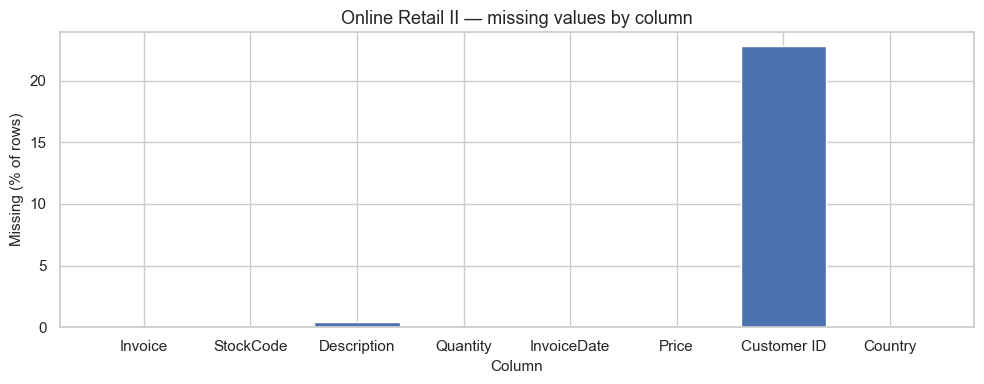

In [4]:
missing = retail_raw.isna().sum()
print("Missing values per column:")
print(pd.DataFrame({"missing": missing, "missing_pct": (missing / len(retail_raw) * 100).round(2)}).to_string())

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(missing.index, missing.values / len(retail_raw) * 100, color=MAIN_COLOR)
ax.set_title("Online Retail II — missing values by column")
ax.set_xlabel("Column")
ax.set_ylabel("Missing (% of rows)")
save_fig("retail_missing_values")
plt.show()

**Interpretation:** about **22.8 %** of lines have no `Customer ID` and 0.4 % have no `Description`. Lines without a
customer are still real sales (e.g. guest checkouts), so they **count towards revenue** for forecasting, but they
**cannot be used for customer segmentation**. Nothing will be imputed: inventing customer IDs would create fake customers.

In [5]:
is_cancellation = retail_raw["Invoice"].str.startswith("C")
print(f"Exact duplicate rows             : {retail_raw.duplicated().sum():,}")
print(f"Cancellation lines (Invoice 'C') : {is_cancellation.sum():,}")
print(f"Bad-debt adjustment lines ('A')  : {retail_raw['Invoice'].str.startswith('A').sum():,}")
print(f"Lines with Price <= 0            : {(retail_raw['Price'] <= 0).sum():,}")
print(f"Non-cancelled lines, Quantity<=0 : {((retail_raw['Quantity'] <= 0) & ~is_cancellation).sum():,}")
print(f"Unique invoices / customers / products: {retail_raw['Invoice'].nunique():,} / "
      f"{retail_raw['Customer ID'].nunique():,} / {retail_raw['StockCode'].nunique():,}")

Exact duplicate rows             : 34,335
Cancellation lines (Invoice 'C') : 19,494
Bad-debt adjustment lines ('A')  : 6
Lines with Price <= 0            : 6,207


Non-cancelled lines, Quantity<=0 : 3,457
Unique invoices / customers / products: 53,628 / 5,942 / 5,305


Some stock codes are not products. The table below lists every code that does not follow the usual product pattern
(5 digits, optionally followed by letters), with its description and total value.

In [6]:
product_pattern = r"^\d{5}[A-Za-z]{0,2}$"
unusual_codes = retail_raw[~retail_raw["StockCode"].str.match(product_pattern)]
unusual_summary = unusual_codes.assign(line_value=unusual_codes["Quantity"] * unusual_codes["Price"]).groupby("StockCode").agg(
    lines=("Invoice", "size"), example_description=("Description", "first"), total_value=("line_value", "sum"))
unusual_summary.sort_values("lines", ascending=False).head(25).round(2)

,lines,example_description,total_value
StockCode,,,
POST,2122,POSTAGE,112341.00
DOT,1446,DOTCOM POSTAGE,322647.47
M,1421,Manual,-82796.32
C2,282,CARRIAGE,13386.00
D,177,Discount,-13484.54
S,104,SAMPLES,-6065.80
BANK CHARGES,102,Bank Charges,-35562.63
ADJUST,67,Adjustment by john on 26/01/2010 16,6835.24
AMAZONFEE,43,AMAZON FEE,-260763.58


**Decision — documented cleaning rules for Online Retail II**

| Rule | Reason |
|---|---|
| Remove exact duplicate rows | Same invoice, product, quantity, time and price twice is a logging duplicate. |
| Remove non-product service codes: `POST`, `DOT`, `C2` (postage/carriage), `M`/`m` (manual), `D` (discount), `S` (samples), `BANK CHARGES`, `AMAZONFEE`, `CRUK` (commission), `ADJUST`, `ADJUST2`, `B` (bad debt), `TEST001`, `TEST002`, and gift vouchers (`gift_…`) | These are fees, accounting entries or tests, not product sales. Codes such as `DCGS…` and `SP1002` are real products and are kept. |
| Remove `A` invoices (bad-debt adjustments) | Accounting entries, not sales. |
| Remove lines with `Price <= 0` | Free items or adjustments with no sale value. |
| Remove non-cancelled lines with `Quantity <= 0` | Stock corrections, not customer transactions. |
| **Keep** cancellations, flagged with `is_cancellation` | Needed to compute **net** revenue (sales minus cancellations). |
| **Keep** lines without `Customer ID` | Real revenue; excluded later only for segmentation. |
| Add `revenue = Quantity × Price` | Cancellation lines have negative quantity, so their revenue is negative. |

In [7]:
SERVICE_CODES = {"POST", "DOT", "C2", "M", "m", "D", "S", "BANK CHARGES", "AMAZONFEE", "CRUK",
                 "ADJUST", "ADJUST2", "B", "TEST001", "TEST002"}

cleaning_log = [("raw lines", len(retail_raw))]
retail = retail_raw.drop_duplicates()
cleaning_log.append(("after removing exact duplicates", len(retail)))
retail = retail[~retail["StockCode"].isin(SERVICE_CODES) & ~retail["StockCode"].str.startswith("gift_")]
cleaning_log.append(("after removing service codes and gift vouchers", len(retail)))
retail = retail[~retail["Invoice"].str.startswith("A")]
cleaning_log.append(("after removing bad-debt adjustments", len(retail)))
retail = retail[retail["Price"] > 0]
cleaning_log.append(("after removing Price <= 0", len(retail)))
retail = retail.assign(is_cancellation=retail["Invoice"].str.startswith("C"))
retail = retail[(retail["Quantity"] > 0) | retail["is_cancellation"]]
cleaning_log.append(("after removing non-cancelled Quantity <= 0", len(retail)))
retail = retail.assign(revenue=retail["Quantity"] * retail["Price"]).sort_values("InvoiceDate").reset_index(drop=True)

cleaning_table = pd.DataFrame(cleaning_log, columns=["step", "rows"])
cleaning_table["rows_removed"] = (-cleaning_table["rows"].diff()).fillna(0).astype(int)
cleaning_table

,step,rows,rows_removed
0,raw lines,1067371,0
1,after removing exact duplicates,1033036,34335
2,after removing service codes and gift vouchers,1027237,5799
3,after removing bad-debt adjustments,1027237,0
4,after removing Price <= 0,1021272,5965
5,after removing non-cancelled Quantity <= 0,1021272,0


In [8]:
sales_lines = retail[~retail["is_cancellation"]]
cancel_lines = retail[retail["is_cancellation"]]
print(f"Sales lines        : {len(sales_lines):,}  | gross revenue £{sales_lines['revenue'].sum():,.0f}")
print(f"Cancellation lines : {len(cancel_lines):,}  | cancelled value £{cancel_lines['revenue'].sum():,.0f}")
print(f"Net revenue        : £{retail['revenue'].sum():,.0f}  "
      f"(cancellations = {-cancel_lines['revenue'].sum() / sales_lines['revenue'].sum():.1%} of gross)")
print(f"Lines with Customer ID: {retail['Customer ID'].notna().mean():.1%} | "
      f"share of net revenue: {retail.loc[retail['Customer ID'].notna(), 'revenue'].sum() / retail['revenue'].sum():.1%}")

Sales lines        : 1,003,357  | gross revenue £19,643,862
Cancellation lines : 17,915  | cancelled value £-716,463
Net revenue        : £18,927,399  (cancellations = 3.6% of gross)
Lines with Customer ID: 77.8% | share of net revenue: 86.4%


**Interpretation:** cleaning removed about 4 % of lines (46,099), mostly exact duplicates (34,335) and non-product
entries. (The bad-debt and zero-quantity rules removed nothing extra because those lines had already been caught by
the service-code and price rules.) Cancellations are worth about **3.6 % of gross sales**. Lines with a known customer
are 78 % of lines but about 86 % of net revenue — guest lines tend to be smaller.

## Step 3 — Explore numeric features and extreme values

`Quantity`, `Price` and line `revenue` are extremely right-skewed, so they are plotted on a log scale.

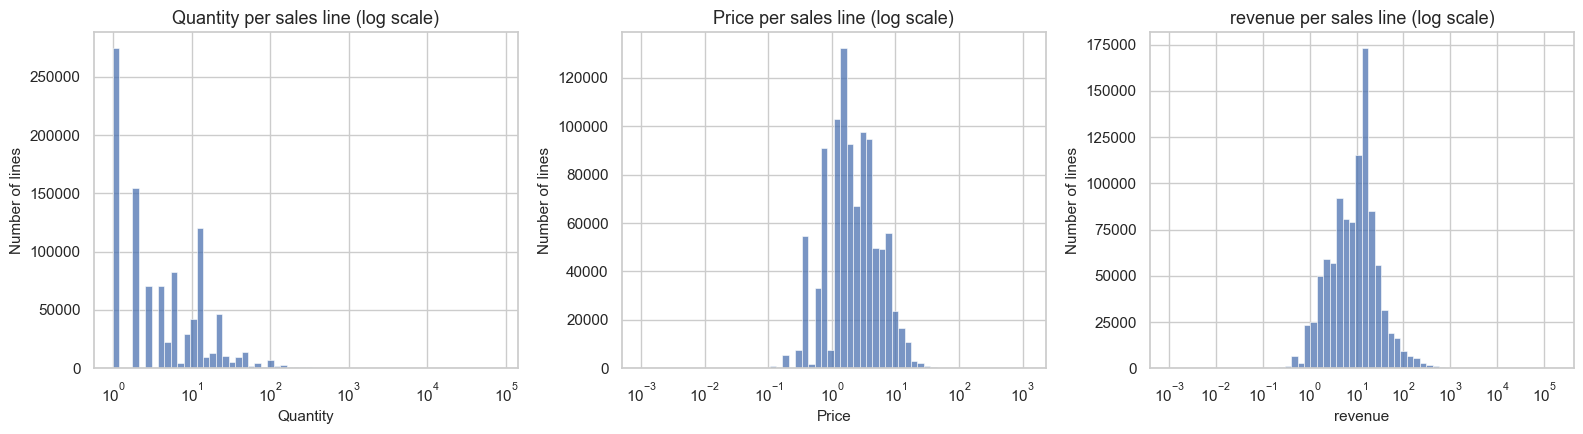

,Quantity,Price,revenue
count,1003357.00,1003357.00,1003357.00
mean,11.15,3.34,19.58
std,128.74,4.75,199.98
min,1.00,0.00,0.00
50%,4.00,2.10,10.08
99%,108.00,16.95,179.00
99.9%,500.00,34.95,763.72
max,80995.00,1157.15,168469.60


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, column in zip(axes, ["Quantity", "Price", "revenue"]):
    sns.histplot(sales_lines[column], bins=60, log_scale=True, ax=ax, color=MAIN_COLOR)
    ax.set_title(f"{column} per sales line (log scale)")
    ax.set_xlabel(column)
    ax.set_ylabel("Number of lines")
save_fig("retail_numeric_histograms")
plt.show()
sales_lines[["Quantity", "Price", "revenue"]].describe(percentiles=[0.5, 0.99, 0.999]).round(2)

In [10]:
print("Largest sales lines and whether a matching cancellation exists for the same customer and product:")
largest = sales_lines.nlargest(6, "revenue")[["Invoice", "InvoiceDate", "StockCode", "Description", "Quantity", "Price", "revenue", "Customer ID"]]
largest["cancelled_qty_same_customer_product"] = [
    -cancel_lines.loc[(cancel_lines["Customer ID"] == row["Customer ID"]) & (cancel_lines["StockCode"] == row["StockCode"]), "Quantity"].sum()
    for _, row in largest.iterrows()]
largest

Largest sales lines and whether a matching cancellation exists for the same customer and product:


,Invoice,InvoiceDate,StockCode,Description,Quantity,Price,revenue,Customer ID,cancelled_qty_same_customer_product
1019799,581483,2011-12-09 09:15:00,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60,16446.0,80995
550456,541431,2011-01-18 10:01:00,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60,12346.0,74215
708202,556444,2011-06-10 15:28:00,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.00,15098.0,60
421138,530715,2010-11-04 11:36:00,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,1.69,15818.40,15838.0,9360
221900,511465,2010-06-08 12:59:00,15044A,PINK PAPER PARASOL,3500,2.55,8925.00,18008.0,0
831730,567423,2011-09-20 11:05:00,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,7144.72,17450.0,0


**Interpretation:** the median sales line is 4 units at about £2.10 (≈ £10), while the very largest lines are
wholesale-sized. The **four largest** lines — including 80,995 paper birds (£168k) and 74,215 ceramic jars (£77k) —
were **cancelled in full** by the same customer, so using **net revenue** removes them automatically. Other large
lines (e.g. 3,500 paper parasols) have no matching cancellation and look like legitimate wholesale purchases, so they are kept.

**Decision:** forecasting uses **net revenue** (sales minus cancellations). Extreme but legitimate lines are not removed.

## Step 4 — Countries, customers and cancellations

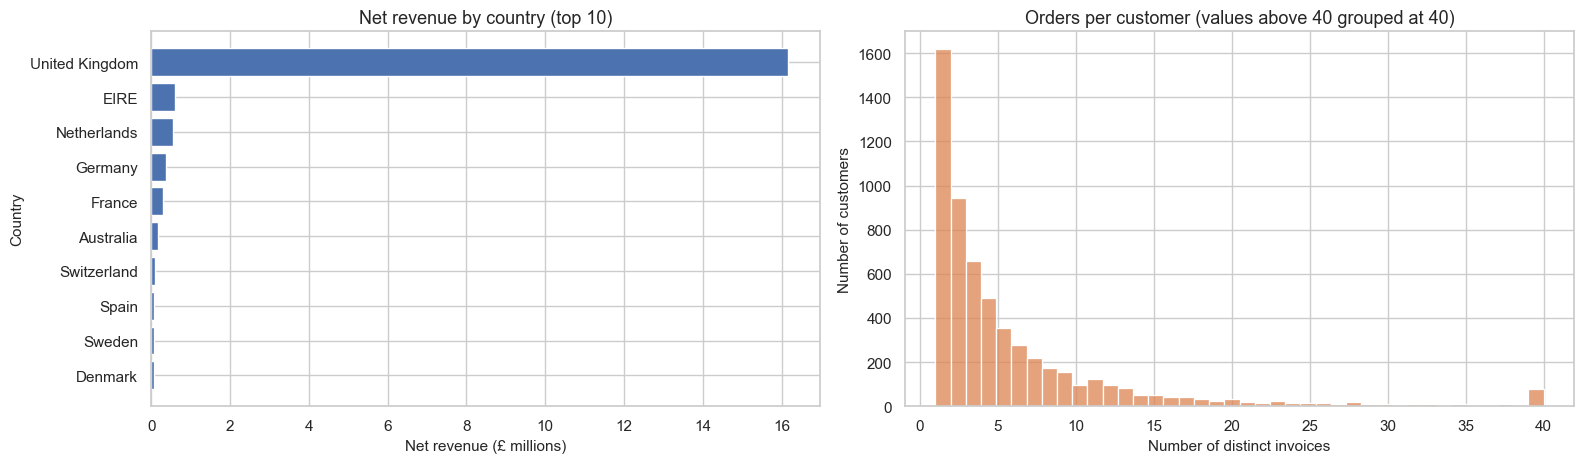

UK share of net revenue: 85.4%
Customers: 5,852 | one-time buyers: 27.6% | median orders: 3


In [11]:
country_revenue = retail.groupby("Country")["revenue"].sum().sort_values(ascending=False)
orders_per_customer = sales_lines.dropna(subset=["Customer ID"]).groupby("Customer ID")["Invoice"].nunique()

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
top_countries = country_revenue.head(10)
axes[0].barh(top_countries.index[::-1], top_countries.values[::-1] / 1e6, color=MAIN_COLOR)
axes[0].set_title("Net revenue by country (top 10)")
axes[0].set_xlabel("Net revenue (£ millions)")
axes[0].set_ylabel("Country")
sns.histplot(orders_per_customer.clip(upper=40), bins=40, ax=axes[1], color=ACCENT_COLOR)
axes[1].set_title("Orders per customer (values above 40 grouped at 40)")
axes[1].set_xlabel("Number of distinct invoices")
axes[1].set_ylabel("Number of customers")
save_fig("retail_country_customers")
plt.show()
print(f"UK share of net revenue: {country_revenue['United Kingdom'] / country_revenue.sum():.1%}")
print(f"Customers: {len(orders_per_customer):,} | one-time buyers: {(orders_per_customer == 1).mean():.1%} | "
      f"median orders: {orders_per_customer.median():.0f}")

**Interpretation:** the United Kingdom produces about 85 % of net revenue. Customer behaviour varies widely: about
28 % of customers bought only once, the median customer placed 3 orders, and a small group placed dozens (many are
wholesalers). This spread in Frequency and Monetary value is exactly what RFM segmentation needs.

## Step 5 — Time patterns (the key question for forecasting)

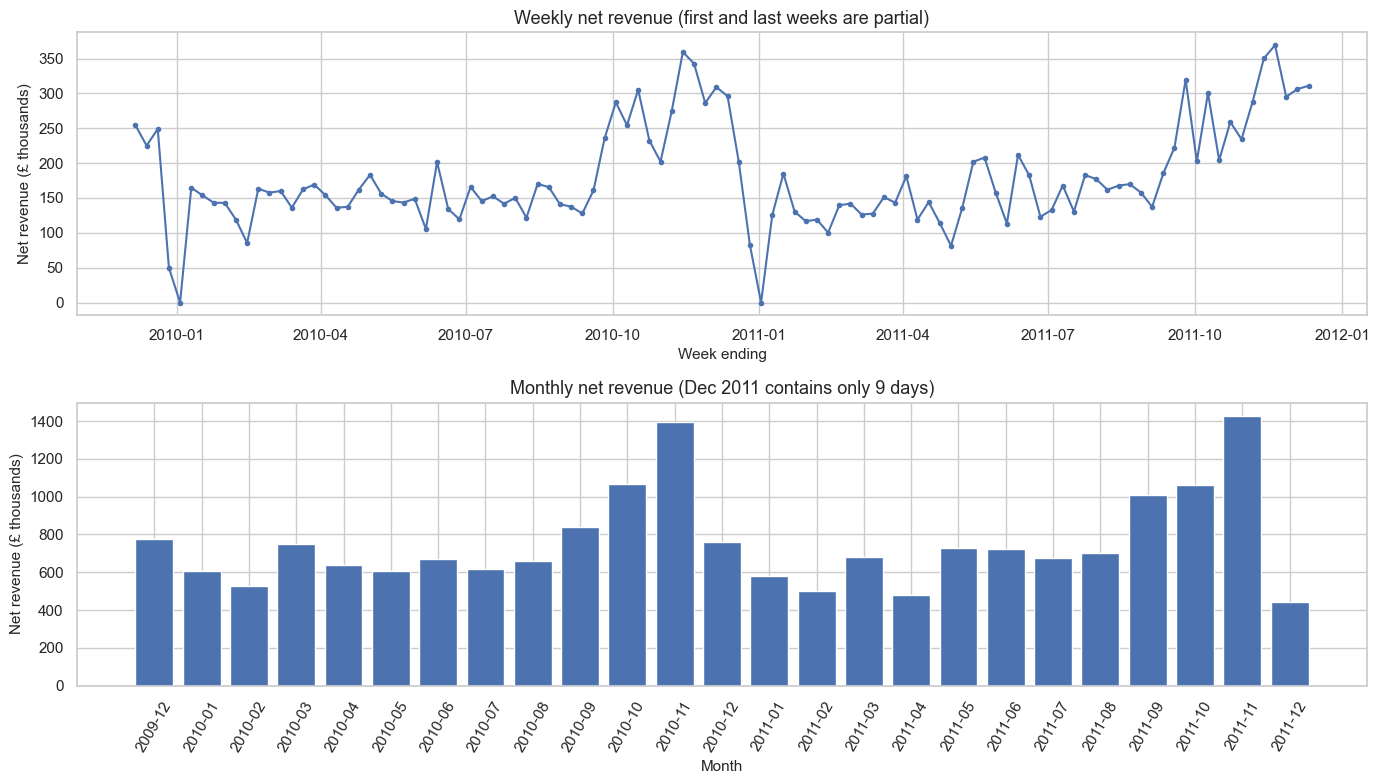

In [12]:
daily_net = retail.set_index("InvoiceDate")["revenue"].resample("D").sum()
weekly_net = daily_net.resample("W-SUN").sum()
monthly_net = daily_net.resample("MS").sum()

fig, axes = plt.subplots(2, 1, figsize=(14, 8))
axes[0].plot(weekly_net.index, weekly_net / 1e3, marker="o", markersize=3, color=MAIN_COLOR)
axes[0].set_title("Weekly net revenue (first and last weeks are partial)")
axes[0].set_xlabel("Week ending")
axes[0].set_ylabel("Net revenue (£ thousands)")
axes[1].bar(monthly_net.index.strftime("%Y-%m"), monthly_net / 1e3, color=MAIN_COLOR)
axes[1].set_title("Monthly net revenue (Dec 2011 contains only 9 days)")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Net revenue (£ thousands)")
axes[1].tick_params(axis="x", rotation=60)
save_fig("retail_revenue_over_time")
plt.show()

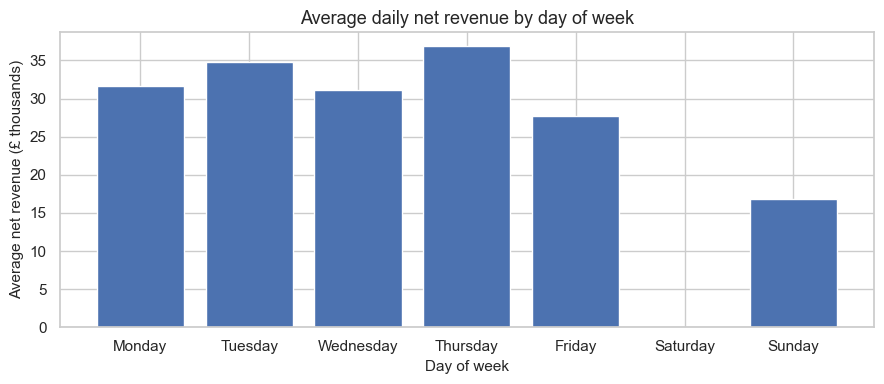

Days with zero revenue by weekday: {'Monday': 11, 'Tuesday': 2, 'Wednesday': 2, 'Thursday': 3, 'Friday': 7, 'Saturday': 104, 'Sunday': 6}


In [13]:
weekday_revenue = daily_net.groupby(daily_net.index.day_name()).mean()
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(weekday_order, weekday_revenue.reindex(weekday_order) / 1e3, color=MAIN_COLOR)
ax.set_title("Average daily net revenue by day of week")
ax.set_xlabel("Day of week")
ax.set_ylabel("Average net revenue (£ thousands)")
save_fig("retail_weekday_pattern")
plt.show()
print("Days with zero revenue by weekday:", (daily_net == 0).groupby(daily_net.index.day_name()).sum().reindex(weekday_order).to_dict())

**Interpretation:**
- Revenue has a **strong, repeating yearly pattern**: it is fairly stable from January to August, then rises sharply
  from September to a peak in **November** in *both* 2010 and 2011 (Christmas-gift wholesale buying), and drops in late December.
- There is a **weekly pattern** too: there is no trading on Saturdays (104 of 104 Saturdays have zero revenue), Sunday
  revenue is about half a weekday's, and Thursday is the strongest day.
- The shop is closed over Christmas / New Year, producing near-zero weeks.

**Decision:** this series has the trend, seasonality and calendar structure that forecasting models can learn — unlike
the dataset in version 1. Forecasting will use **complete weeks**, calendar features, and a **seasonal-naive** baseline
(same week last year), which is the fair baseline for seasonal data.

## Step 6 — Save the cleaned Online Retail II data

The cleaned table is saved compressed to `data/processed/online_retail_clean.csv.gz`. Notebooks 01 and 03 load this
file, so the cleaning rules above are applied once and consistently.

In [14]:
retail_columns = ["Invoice", "StockCode", "Description", "Quantity", "InvoiceDate", "Price", "Customer ID", "Country",
                  "is_cancellation", "revenue"]
retail[retail_columns].to_csv(PROCESSED_DIR / "online_retail_clean.csv.gz", index=False)
cleaning_table.to_csv(TABLE_DIR / "00_retail_cleaning_log.csv", index=False)
print("Saved", PROCESSED_DIR / "online_retail_clean.csv.gz", retail.shape)

Saved C:\Users\ombho\Desktop\mlcie2\ecommerce-ml-cie-v2\data\processed\online_retail_clean.csv.gz (1021272, 10)


# Part B — E-commerce Fraud Data (Module B)

## Step 1 — Load and inspect

Each row is a user's **first purchase** on an e-commerce site. Columns: `user_id`, `signup_time`, `purchase_time`,
`purchase_value` (US$), `device_id`, `source` (SEO / Ads / Direct), `browser`, `sex`, `age`, `ip_address`, and
`class` (**1 = fraudulent, 0 = legitimate**).

*Provenance note:* this dataset is widely used in data-science courses and take-home challenges and is mirrored in
many public repositories; its original publisher and licence are not documented, so it is used here for educational purposes only.

In [15]:
fraud = pd.read_csv(FRAUD_PATH, parse_dates=["signup_time", "purchase_time"])
print("Shape:", fraud.shape)
fraud.head()

Shape: (151112, 11)


,user_id,signup_time,purchase_time,purchase_value,device_id,source,browser,sex,age,ip_address,class
0,22058,2015-02-24 22:55:49,2015-04-18 02:47:11,34,QVPSPJUOCKZAR,SEO,Chrome,M,39,7.327584e+08,0
1,333320,2015-06-07 20:39:50,2015-06-08 01:38:54,16,EOGFQPIZPYXFZ,Ads,Chrome,F,53,3.503114e+08,0
2,1359,2015-01-01 18:52:44,2015-01-01 18:52:45,15,YSSKYOSJHPPLJ,SEO,Opera,M,53,2.621474e+09,1
3,150084,2015-04-28 21:13:25,2015-05-04 13:54:50,44,ATGTXKYKUDUQN,SEO,Safari,M,41,3.840542e+09,0
4,221365,2015-07-21 07:09:52,2015-09-09 18:40:53,39,NAUITBZFJKHWW,Ads,Safari,M,45,4.155831e+08,0


In [16]:
print("Missing values      :", int(fraud.isna().sum().sum()))
print("Duplicate rows      :", fraud.duplicated().sum())
print("Duplicate user_id   :", fraud["user_id"].duplicated().sum())
print("Signup range        :", fraud["signup_time"].min(), "to", fraud["signup_time"].max())
print("Purchase range      :", fraud["purchase_time"].min(), "to", fraud["purchase_time"].max())
print("Purchase before signup:", int((fraud["purchase_time"] < fraud["signup_time"]).sum()))
for column in ["source", "browser", "sex"]:
    print(f"{column:8s}:", sorted(fraud[column].unique()))
print(f"Fraud rate          : {fraud['class'].mean():.2%} ({fraud['class'].sum():,} fraudulent purchases)")

Missing values      : 0
Duplicate rows      : 0
Duplicate user_id   : 0
Signup range        : 2015-01-01 00:00:42 to 2015-08-18 04:40:29
Purchase range      : 2015-01-01 00:00:44 to 2015-12-16 02:56:05
Purchase before signup: 0
source  : ['Ads', 'Direct', 'SEO']
browser : ['Chrome', 'FireFox', 'IE', 'Opera', 'Safari']


sex     : ['F', 'M']
Fraud rate          : 9.36% (14,151 fraudulent purchases)


**Interpretation:** 151,112 purchases, no missing values, no duplicates, one row per user, and no purchase happens
before its signup. **9.4 % of purchases are labelled fraudulent** — imbalanced, but with ~14,000 fraud cases there is
plenty to evaluate against.

**Decision:** no cleaning is needed. `user_id`, `device_id` and `ip_address` are identifiers and will never be used as
raw numeric features, but *how many users share a device or IP* can be engineered safely in notebook 02.

## Step 2 — Which behaviours separate fraud from legitimate purchases?

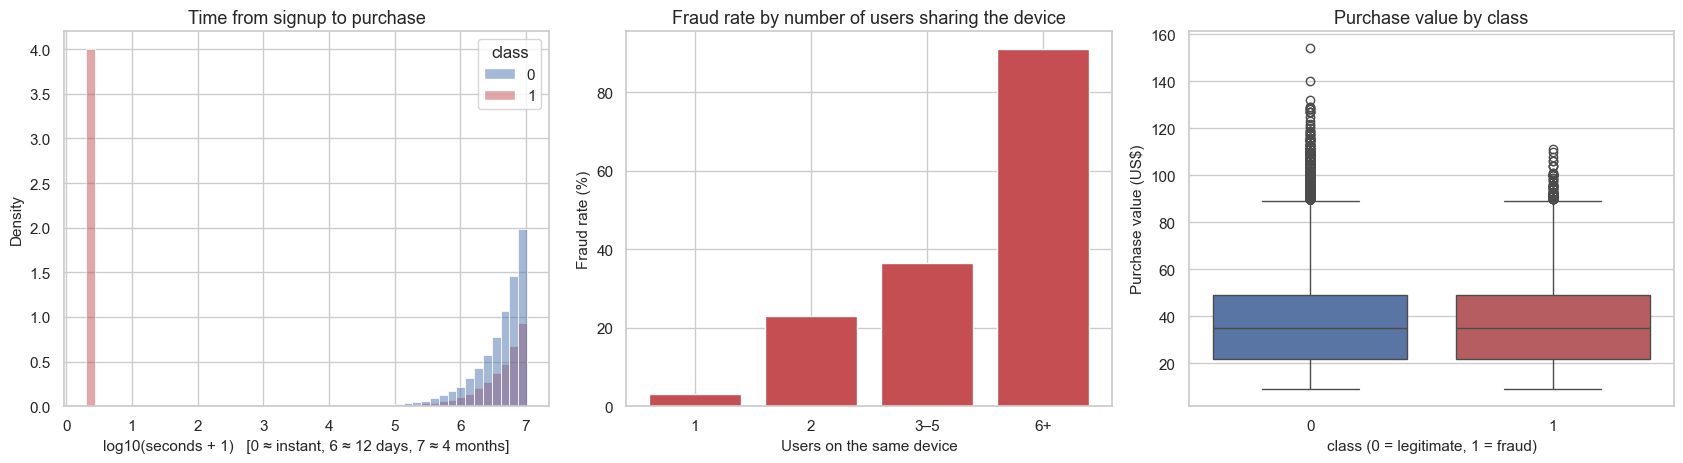

Purchases within 1 second of signup: 7,600 | fraud rate 100.0%
Fraud rate by users on device: {'1': 3.0, '2': 22.9, '3–5': 36.5, '6+': 91.0}
Fraud rate by source : {'Ads': 9.2, 'Direct': 10.5, 'SEO': 8.9}
Fraud rate by browser: {'Chrome': 9.9, 'FireFox': 9.5, 'IE': 8.7, 'Opera': 8.9, 'Safari': 9.0}


In [17]:
fraud["seconds_signup_to_purchase"] = (fraud["purchase_time"] - fraud["signup_time"]).dt.total_seconds()
fraud["users_on_device"] = fraud.groupby("device_id")["user_id"].transform("count")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
sns.histplot(data=fraud, x=np.log10(fraud["seconds_signup_to_purchase"] + 1), hue="class", bins=50,
             stat="density", common_norm=False, palette=[MAIN_COLOR, FRAUD_COLOR], ax=axes[0])
axes[0].set_title("Time from signup to purchase")
axes[0].set_xlabel("log10(seconds + 1)   [0 ≈ instant, 6 ≈ 12 days, 7 ≈ 4 months]")
axes[0].set_ylabel("Density")

device_bins = pd.cut(fraud["users_on_device"], [0, 1, 2, 5, 100], labels=["1", "2", "3–5", "6+"])
device_fraud = fraud.groupby(device_bins, observed=True)["class"].mean()
axes[1].bar(device_fraud.index.astype(str), device_fraud.values * 100, color=FRAUD_COLOR)
axes[1].set_title("Fraud rate by number of users sharing the device")
axes[1].set_xlabel("Users on the same device")
axes[1].set_ylabel("Fraud rate (%)")

sns.boxplot(data=fraud, x="class", y="purchase_value", hue="class", palette=[MAIN_COLOR, FRAUD_COLOR], legend=False, ax=axes[2])
axes[2].set_title("Purchase value by class")
axes[2].set_xlabel("class (0 = legitimate, 1 = fraud)")
axes[2].set_ylabel("Purchase value (US$)")
save_fig("fraud_signals")
plt.show()

print(f"Purchases within 1 second of signup: {(fraud['seconds_signup_to_purchase'] <= 1).sum():,} "
      f"| fraud rate {fraud.loc[fraud['seconds_signup_to_purchase'] <= 1, 'class'].mean():.1%}")
print("Fraud rate by users on device:", (device_fraud * 100).round(1).to_dict())
print("Fraud rate by source :", (fraud.groupby("source")["class"].mean() * 100).round(1).to_dict())
print("Fraud rate by browser:", (fraud.groupby("browser")["class"].mean() * 100).round(1).to_dict())

**Interpretation:**
- **Speed:** 7,600 purchases happened within one second of signup and **every one of them is fraud** — a typical sign of
  automated (bot) accounts. Legitimate users usually take days or weeks.
- **Shared devices:** when only one user uses a device the fraud rate is about 3 %, but when 6+ users share a device it
  is about 91 %.
- **Purchase value, source, browser and sex** look almost identical for both classes, so they carry little signal.

**Decision:** the anomaly features in notebook 02 will focus on behaviour (timing, device/IP sharing) rather than
demographics. Device and IP sharing will be computed **only from earlier purchases** so no future information leaks into a transaction's score.

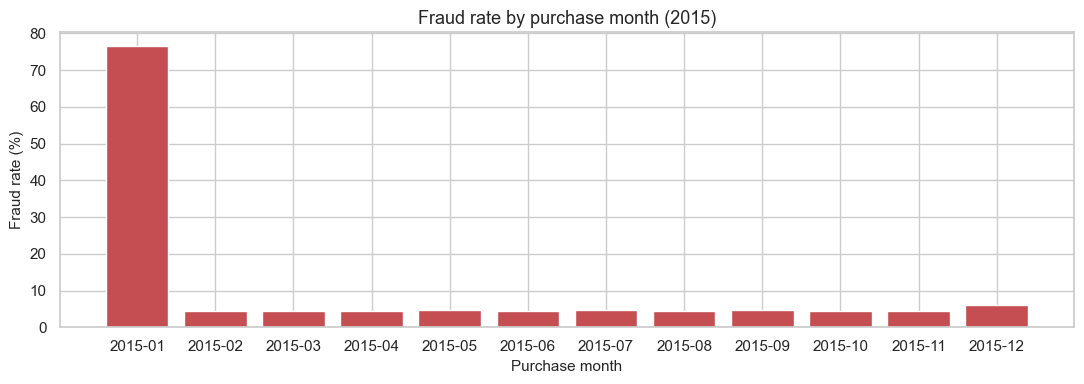

purchase_time,2015-01,2015-02,2015-03,2015-04,2015-05,2015-06,2015-07,2015-08,2015-09,2015-10,2015-11,2015-12
purchases,10097.000,6449.000,12090.000,16551.000,19364.000,18908.000,19507.000,18662.000,14347.000,9815.000,4743.000,579.00
fraud_rate,0.765,0.045,0.045,0.045,0.048,0.045,0.046,0.045,0.046,0.045,0.046,0.06


In [18]:
monthly_fraud = fraud.groupby(fraud["purchase_time"].dt.to_period("M"))["class"].agg(purchases="size", fraud_rate="mean")
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(monthly_fraud.index.astype(str), monthly_fraud["fraud_rate"] * 100, color=FRAUD_COLOR)
ax.set_title("Fraud rate by purchase month (2015)")
ax.set_xlabel("Purchase month")
ax.set_ylabel("Fraud rate (%)")
save_fig("fraud_by_month")
plt.show()
monthly_fraud.T.round(3)

**Interpretation:** January has a fraud rate of about 76 % (a burst of instant bot purchases), while every other month
sits around 4.5–6 %. A model evaluated only on January would look unrealistically good.

**Decision:** notebook 02 evaluates on a **later time period** (the last months of purchases), which reflects the
normal ~5 % fraud level and tests whether the method generalises beyond the January burst.

## Conclusion — data overview and module plan

In [19]:
overview = pd.DataFrame([
    {"dataset": "Online Retail II", "raw_rows": len(retail_raw), "clean_rows": len(retail),
     "period": f"{retail['InvoiceDate'].min().date()} to {retail['InvoiceDate'].max().date()}",
     "customers": int(retail["Customer ID"].nunique()), "label": "none (unsupervised)", "modules": "A, C"},
    {"dataset": "E-commerce Fraud Data", "raw_rows": len(fraud), "clean_rows": len(fraud),
     "period": f"{fraud['purchase_time'].min().date()} to {fraud['purchase_time'].max().date()}",
     "customers": int(fraud["user_id"].nunique()), "label": f"class (fraud rate {fraud['class'].mean():.2%})", "modules": "B"},
])
overview.to_csv(TABLE_DIR / "00_data_overview.csv", index=False)
overview

,dataset,raw_rows,clean_rows,period,customers,label,modules
0,Online Retail II,1067371,1021272,2009-12-01 to 2011-12-09,5875,none (unsupervised),"A, C"
1,E-commerce Fraud Data,151112,151112,2015-01-01 to 2015-12-16,151112,class (fraud rate 9.36%),B


| Module | Dataset | Fields used |
|---|---|---|
| **A. Revenue forecasting** | Online Retail II (cleaned) | `InvoiceDate`, `revenue` (net) → daily and weekly net revenue |
| **B. Anomaly & risk detection** | Fraud Data | timing (signup → purchase, hour, weekday), `purchase_value`, `age`, prior device/IP sharing; `class` **only for evaluation** |
| **C. Customer segmentation & value** | Online Retail II (cleaned, rows with `Customer ID`) | `Customer ID`, `Invoice`, `InvoiceDate`, `revenue` → RFM; a later time window gives a genuine future-spend target |

**Key findings:** Online Retail II needed documented cleaning (duplicates, fees, cancellations) and shows strong
yearly and weekly seasonality; the fraud dataset is clean, has a real label, and fraud is driven by bot-like timing and device sharing.